In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("DemographicData.csv")
df

,Country Name,Country Code,Birth rate,Internet users,Income Group
0,Aruba,ABW,10.244,78.9,High income
1,Afghanistan,AFG,35.253,5.9,Low income
2,Angola,AGO,45.985,19.1,Upper middle income
3,Albania,ALB,12.877,57.2,Upper middle income
4,United Arab Emirates,ARE,11.044,88.0,High income
...,...,...,...,...,...
190,"Yemen, Rep.",YEM,32.947,20.0,Lower middle income
191,South Africa,ZAF,20.850,46.5,Upper middle income
192,"Congo, Dem. Rep.",COD,42.394,2.2,Low income
193,Zambia,ZMB,40.471,15.4,Lower middle income


In [3]:
x=df['Birth rate'].head()
x

0    10.244
1    35.253
2    45.985
3    12.877
4    11.044
Name: Birth rate, dtype: float64

In [4]:
y=df['Country Name'].head()
y

0                   Aruba
1             Afghanistan
2                  Angola
3                 Albania
4    United Arab Emirates
Name: Country Name, dtype: object

Mathplot


scatter plot

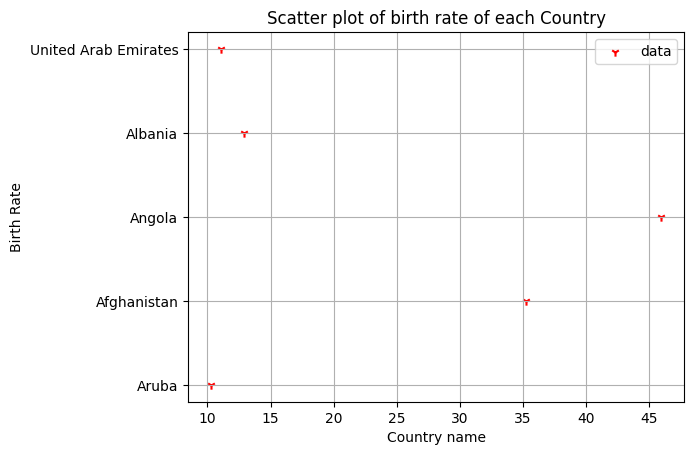

In [5]:
plt.scatter(x,y,marker='1',color='red',label='data')
plt.xlabel('Country name')
plt.ylabel('Birth Rate')
plt.title('Scatter plot of birth rate of each Country')
plt.grid(True)
plt.legend()
plt.show()

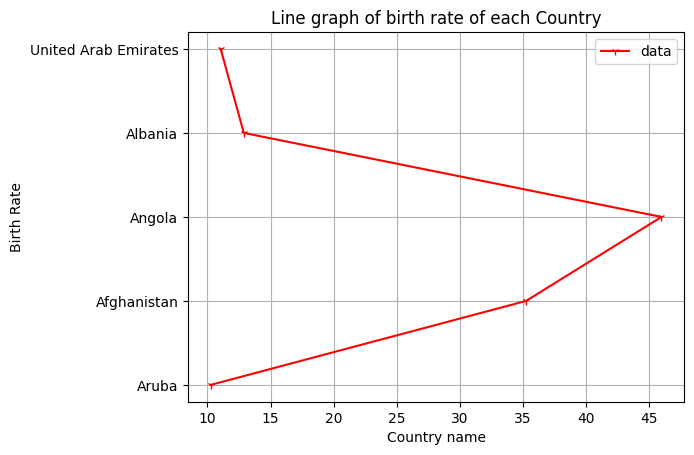

In [6]:
plt.plot(x,y,marker='1',color='red',label='data')
plt.xlabel('Country name')
plt.ylabel('Birth Rate')
plt.title('Line graph of birth rate of each Country')
plt.grid(True)
plt.legend()
plt.show()

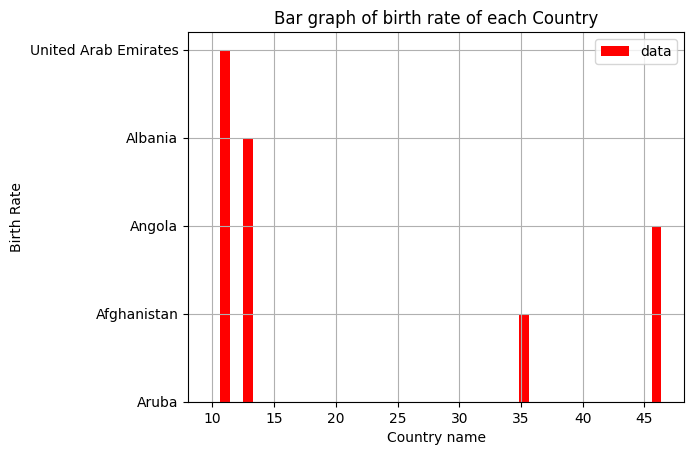

In [7]:
plt.bar(x,y,color='red',label='data')
plt.xlabel('Country name')
plt.ylabel('Birth Rate')
plt.title('Bar graph of birth rate of each Country')
plt.grid(True)
plt.legend()
plt.show()

In [8]:
import seaborn as sb

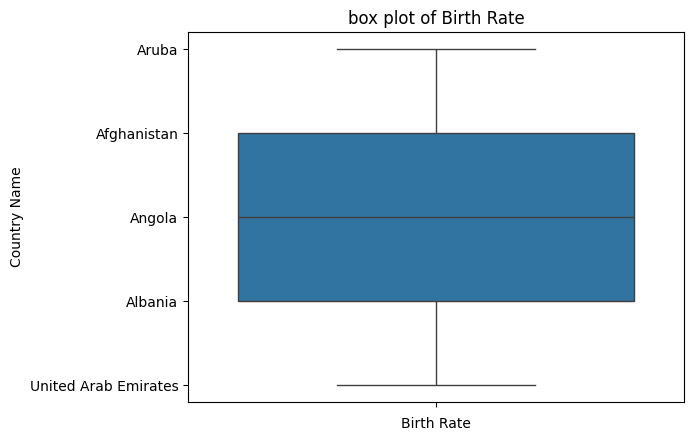

In [9]:
sb.boxplot(y)
plt.xlabel("Birth Rate")
plt.title("box plot of Birth Rate")
plt.show()

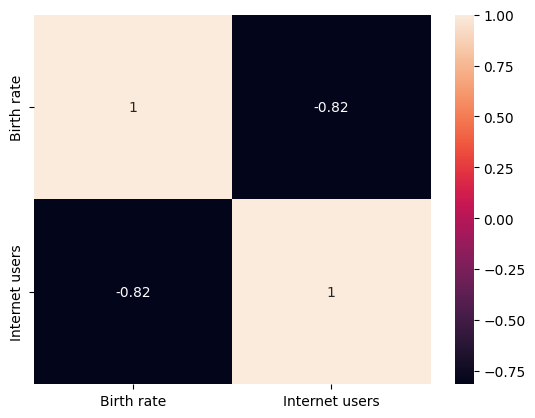

In [10]:
numdf=df.select_dtypes(include='number')
sb.heatmap(numdf.corr(),annot=True)
plt.show()

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import pickle
import os
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [12]:
df=pd.read_csv("DemographicData.csv")
df

,Country Name,Country Code,Birth rate,Internet users,Income Group
0,Aruba,ABW,10.244,78.9,High income
1,Afghanistan,AFG,35.253,5.9,Low income
2,Angola,AGO,45.985,19.1,Upper middle income
3,Albania,ALB,12.877,57.2,Upper middle income
4,United Arab Emirates,ARE,11.044,88.0,High income
...,...,...,...,...,...
190,"Yemen, Rep.",YEM,32.947,20.0,Lower middle income
191,South Africa,ZAF,20.850,46.5,Upper middle income
192,"Congo, Dem. Rep.",COD,42.394,2.2,Low income
193,Zambia,ZMB,40.471,15.4,Lower middle income


In [13]:
df['Income Group'].unique()

array(['High income', 'Low income', 'Upper middle income',
       'Lower middle income'], dtype=object)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    195 non-null    object 
 1   Country Code    195 non-null    object 
 2   Birth rate      195 non-null    float64
 3   Internet users  195 non-null    float64
 4   Income Group    195 non-null    object 
dtypes: float64(2), object(3)
memory usage: 7.7+ KB


In [15]:
df.isnull().sum()

Country Name      0
Country Code      0
Birth rate        0
Internet users    0
Income Group      0
dtype: int64

In [16]:
df.duplicated().sum()

0

In [17]:
df.nunique()

Country Name      195
Country Code      195
Birth rate        177
Internet users    181
Income Group        4
dtype: int64

In [18]:
le = LabelEncoder()
df['Country Name'] = le.fit_transform(df['Country Name'])
df['Country Code'] = le.fit_transform(df['Country Code'])
df['Income Group'] = le.fit_transform(df['Income Group'])
df

,Country Name,Country Code,Birth rate,Internet users,Income Group
0,7,0,10.244,78.9,0
1,0,1,35.253,5.9,1
2,3,2,45.985,19.1,3
3,1,3,12.877,57.2,3
4,182,4,11.044,88.0,0
...,...,...,...,...,...
190,192,191,32.947,20.0,2
191,158,192,20.850,46.5,3
192,40,36,42.394,2.2,1
193,193,193,40.471,15.4,2


In [19]:
x = df.drop(['Income Group'],axis=1)
x

,Country Name,Country Code,Birth rate,Internet users
0,7,0,10.244,78.9
1,0,1,35.253,5.9
2,3,2,45.985,19.1
3,1,3,12.877,57.2
4,182,4,11.044,88.0
...,...,...,...,...
190,192,191,32.947,20.0
191,158,192,20.850,46.5
192,40,36,42.394,2.2
193,193,193,40.471,15.4


In [20]:
y = df['Income Group']
y

0      0
1      1
2      3
3      3
4      0
      ..
190    2
191    3
192    1
193    2
194    1
Name: Income Group, Length: 195, dtype: int32

<Axes: xlabel='Income Group', ylabel='count'>

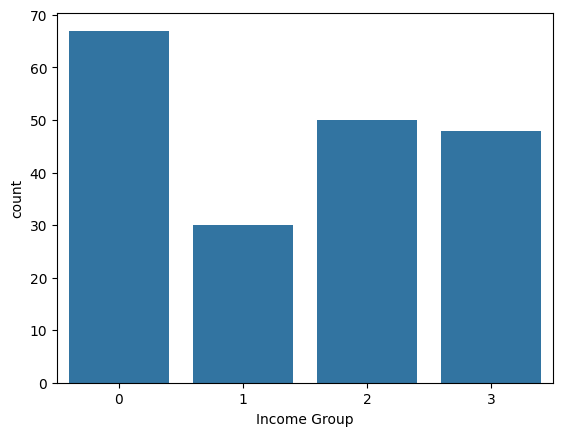

In [21]:
sns.countplot(x=y)

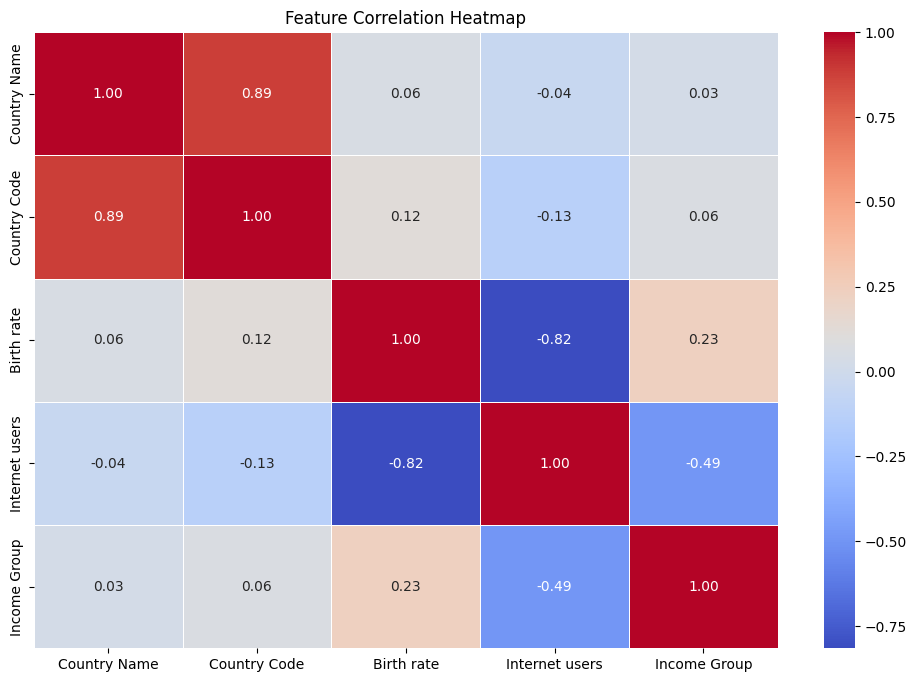

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Show the heatmap
plt.title("Feature Correlation Heatmap")
plt.show()

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)

In [24]:
x_train.shape

(156, 4)

In [25]:
x_test.shape

(39, 4)

In [26]:
y_train.shape

(156,)

In [27]:
y_test.shape

(39,)

In [28]:
labels = ['High income' , 'Low income', 'Upper middle income','Lower middle income']

In [29]:
precision = []
recall = []
fscore = []
accuracy = []

#function to calculate various metrics such as accuracy, precision etc
def PerformanceMetrics(algorithm, predict, testY):
    testY = testY.astype('int')
    predict = predict.astype('int')
    p = precision_score(testY, predict,average='macro') * 100
    r = recall_score(testY, predict,average='macro') * 100
    f = f1_score(testY, predict,average='macro') * 100
    a = accuracy_score(testY,predict)*100 
    accuracy.append(a)
    precision.append(p)
    recall.append(r)
    fscore.append(f)
    print(algorithm+' Accuracy    : '+str(a))
    print(algorithm+' Precision   : '+str(p))
    print(algorithm+' Recall      : '+str(r))
    print(algorithm+' FSCORE      : '+str(f))
    print(f"\n{algorithm} Classification Report:\n")
    print(classification_report(testY, predict, target_names=labels))
    conf_matrix = confusion_matrix(testY, predict) 
    plt.figure(figsize =(5, 5)) 
    ax = sns.heatmap(conf_matrix, xticklabels = labels, yticklabels = labels, annot = True, cmap="Blues" ,fmt ="g");
    ax.set_ylim([0,len(labels)])
    plt.title(algorithm+" Confusion matrix") 
    plt.ylabel('True class') 
    plt.xlabel('Predicted class') 
    plt.show()


Logistic Regression trained and model weights saved.
Logistic Regression Accuracy    : 23.076923076923077
Logistic Regression Precision   : 5.769230769230769
Logistic Regression Recall      : 25.0
Logistic Regression FSCORE      : 9.375

Logistic Regression Classification Report:

                     precision    recall  f1-score   support

        High income       0.23      1.00      0.38         9
         Low income       0.00      0.00      0.00        10
Upper middle income       0.00      0.00      0.00         9
Lower middle income       0.00      0.00      0.00        11

           accuracy                           0.23        39
          macro avg       0.06      0.25      0.09        39
       weighted avg       0.05      0.23      0.09        39



C:\Users\Balu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\Balu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Balu\AppData\Local\Progra

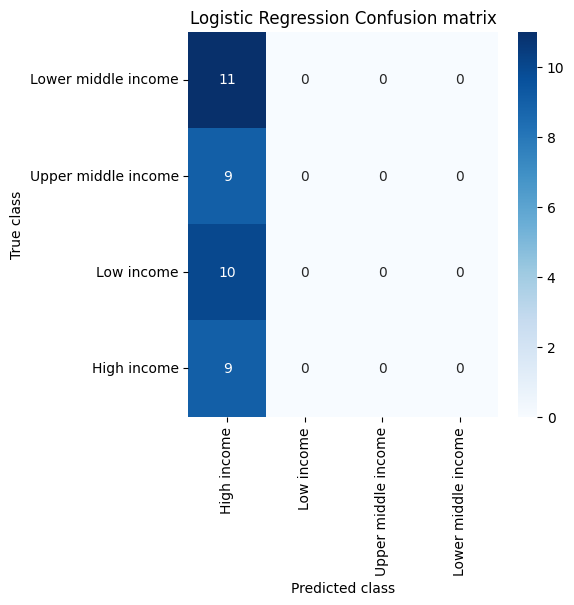

In [30]:
from sklearn.linear_model import LogisticRegression
model = 'logistic_regression.pkl'
if os.path.exists(model):
    # Load the model from the pkl file
    logistic_regression = joblib.load(model)
    predict = logistic_regression.predict(x_test)
    PerformanceMetrics("Logistic Regression", predict, y_test)
else:
    logistic_regression = LogisticRegression(max_iter=1)
    # Train the classifier on the training data
    logistic_regression.fit(x_train, y_train)
    # Make predictions on the test data
    predict = logistic_regression.predict(x_test)
    joblib.dump(logistic_regression, model)
    print("Logistic Regression trained and model weights saved.")
    PerformanceMetrics("Logistic Regression", predict, y_test)

KNeighborsClassifier trained and model saved.
KNeighborsClassifier Accuracy    : 53.84615384615385
KNeighborsClassifier Precision   : 58.94230769230769
KNeighborsClassifier Recall      : 55.15151515151515
KNeighborsClassifier FSCORE      : 53.7799043062201

KNeighborsClassifier Classification Report:

                     precision    recall  f1-score   support

        High income       0.80      0.89      0.84         9
         Low income       0.50      0.60      0.55        10
Upper middle income       0.31      0.44      0.36         9
Lower middle income       0.75      0.27      0.40        11

           accuracy                           0.54        39
          macro avg       0.59      0.55      0.54        39
       weighted avg       0.60      0.54      0.53        39



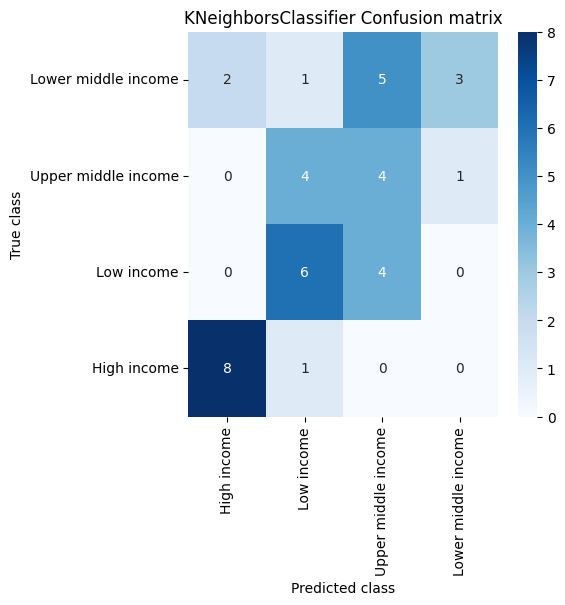

In [31]:
from sklearn.neighbors import KNeighborsClassifier
model_path = 'KNeighborsClassifier.pkl'
if os.path.exists(model_path):
    # Load pretrained model
    knn_model = joblib.load(model_path)
    predict = knn_model.predict(x_test)
    PerformanceMetrics("KNeighborsClassifier", predict, y_test)
else:
    # Create and train new model
    knn_model = KNeighborsClassifier()   # no max_iter
    knn_model.fit(x_train, y_train)
    # Predict
    predict = knn_model.predict(x_test)
    # Save model
    joblib.dump(knn_model, model_path)
    print("KNeighborsClassifier trained and model saved.")
    PerformanceMetrics("KNeighborsClassifier", predict, y_test)


DecisionTreeClassifier trained and model saved.
DecisionTreeClassifier Accuracy    : 69.23076923076923
DecisionTreeClassifier Precision   : 74.20751633986929
DecisionTreeClassifier Recall      : 68.23232323232324
DecisionTreeClassifier FSCORE      : 69.05683325961964

DecisionTreeClassifier Classification Report:

                     precision    recall  f1-score   support

        High income       0.75      0.67      0.71         9
         Low income       0.89      0.80      0.84        10
Upper middle income       0.80      0.44      0.57         9
Lower middle income       0.53      0.82      0.64        11

           accuracy                           0.69        39
          macro avg       0.74      0.68      0.69        39
       weighted avg       0.73      0.69      0.69        39



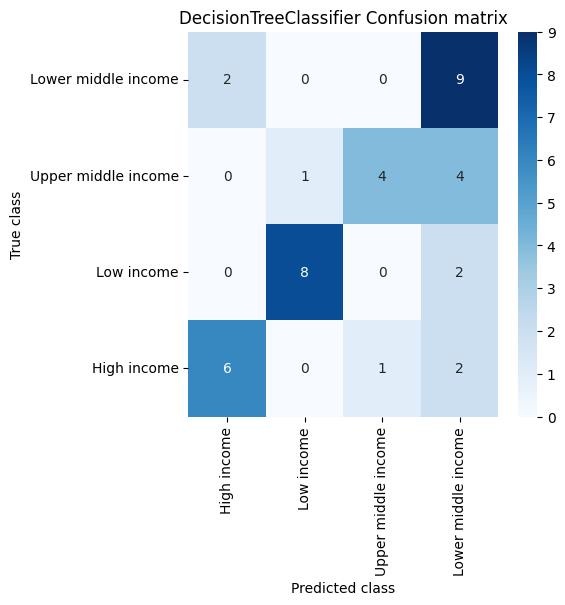

In [32]:
from sklearn.tree import DecisionTreeClassifier
model_path = 'DecisionTreeClassifier.pkl'
if os.path.exists(model_path):
    # Load pretrained model
    dt_model = joblib.load(model_path)
    predict = dt_model.predict(x_test)
    PerformanceMetrics("DecisionTreeClassifier", predict, y_test)
else:
    # Create and train new model
    dt_model = DecisionTreeClassifier()   # you can add hyperparameters if you want
    dt_model.fit(x_train, y_train)
    # Predict
    predict = dt_model.predict(x_test)
    # Save model
    joblib.dump(dt_model, model_path)
    print("DecisionTreeClassifier trained and model saved.")
    PerformanceMetrics("DecisionTreeClassifier", predict, y_test)


RandomForestClassifier trained and model saved.
RandomForestClassifier Accuracy    : 61.53846153846154
RandomForestClassifier Precision   : 62.84090909090909
RandomForestClassifier Recall      : 61.41414141414141
RandomForestClassifier FSCORE      : 61.9327731092437

RandomForestClassifier Classification Report:

                     precision    recall  f1-score   support

        High income       0.75      0.67      0.71         9
         Low income       0.80      0.80      0.80        10
Upper middle income       0.36      0.44      0.40         9
Lower middle income       0.60      0.55      0.57        11

           accuracy                           0.62        39
          macro avg       0.63      0.61      0.62        39
       weighted avg       0.63      0.62      0.62        39



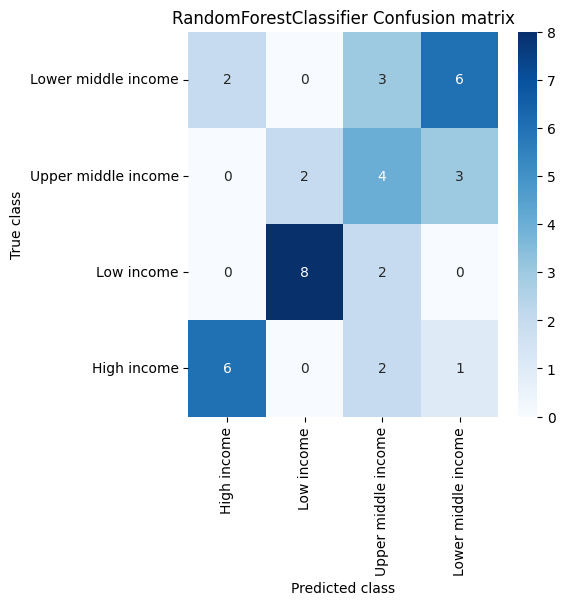

In [33]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

label_encoders = {}

for col in df.columns:
    if df[col].dtype == 'object':  # If column contains non-numeric data
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le
